# Структура продаж музыкальных треков в 2020 году

**Вопрос:** чем отличаются продажи `rock` и остальных жанров по месяцам 2020 года? Это самостоятельный набор данных, не относящийся к сервису доставки из исследования A.

## 1. Загрузка данных из SQLite

Берём чеки, покупателей, треки и жанры. Тяжёлые жанры объединяем в `rock`. Видео исключаем. В SQL используем `JOIN`, `CASE` и фильтр по дате.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect('chinook.db')
query = """SELECT
    il.invoice_line_id,
    i.invoice_id,
    i.customer_id,
    i.invoice_date,
    t.track_id,
    CASE
        WHEN g.name IN ('Rock', 'Alternative & Punk', 'Metal',
                        'Alternative', 'Heavy Metal') THEN 'rock'
        ELSE 'others'
    END AS genre_group,
    il.quantity,
    il.unit_price,
    il.quantity * il.unit_price AS amount
FROM invoice AS i
JOIN invoice_line AS il ON il.invoice_id = i.invoice_id
JOIN track AS t ON t.track_id = il.track_id
JOIN genre AS g ON g.genre_id = t.genre_id
WHERE i.invoice_date >= '2020-01-01'
  AND i.invoice_date < '2021-01-01'
  AND t.media_type_id <> 3
ORDER BY i.invoice_date, il.invoice_line_id"""
df = pd.read_sql_query(query, conn)
conn.close()
print('Строк:', len(df), '| Уникальных позиций чека:', df.invoice_line_id.nunique())
df.head()

Строк: 1150 | Уникальных позиций чека: 1150


,invoice_line_id,invoice_id,customer_id,invoice_date,track_id,genre_group,quantity,unit_price,amount
0,3608,465,21,2020-01-12 00:00:00,149,rock,1,0.99,0.99
1,3609,465,21,2020-01-12 00:00:00,150,rock,1,0.99,0.99
2,3610,465,21,2020-01-12 00:00:00,151,rock,1,0.99,0.99
3,3611,465,21,2020-01-12 00:00:00,152,rock,1,0.99,0.99
4,3612,465,21,2020-01-12 00:00:00,153,rock,1,0.99,0.99


## 2. Проверка качества данных

Проверяем пропуски, повторение идентификатора позиции чека, корректность цен и дат. Повторение пары `invoice_id` + `track_id` **не обязательно ошибка**: один трек может встречаться в чеке более одного раза. Поэтому не удаляем такие строки без проверки первичного ключа.

In [2]:
print('Пропуски:', int(df.isna().sum().sum()))
print('Повторы invoice_line_id:', int(df.invoice_line_id.duplicated().sum()))
print('Повторы (invoice_id, track_id):', int(df.duplicated(['invoice_id', 'track_id']).sum()))
print('Некорректная стоимость:', int(((df.quantity <= 0) | (df.unit_price <= 0)).sum()))
print('Диапазон дат:', df.invoice_date.min(), '—', df.invoice_date.max())
assert not df.invoice_line_id.duplicated().any()
assert df[['invoice_line_id','invoice_id','customer_id','invoice_date','genre_group','quantity','unit_price']].notna().all().all()

Пропуски: 0
Повторы invoice_line_id: 0
Повторы (invoice_id, track_id): 2
Некорректная стоимость: 0
Диапазон дат: 2020-01-12 00:00:00 — 2020-12-30 00:00:00


## 3. Метрики за год

Для каждой категории считаем число купленных треков, уникальных чеков, уникальных покупателей и сумму покупок. Покупатель, приобретавший музыку обоих типов, входит в обе категории. Чеки по категориям тоже могут пересекаться; их нельзя суммировать как число всех чеков.

In [3]:
annual = (df.groupby('genre_group', as_index=False)
          .agg(tracks=('quantity','sum'),
               receipts=('invoice_id','nunique'),
               buyers=('customer_id','nunique'),
               revenue=('amount','sum')))
annual['share_of_tracks_pct'] = (100*annual.tracks/annual.tracks.sum()).round(1)
annual.sort_values('tracks', ascending=False)

,genre_group,tracks,receipts,buyers,revenue,share_of_tracks_pct
1,rock,912,141,57,902.88,79.3
0,others,238,83,49,235.62,20.7


## 4. Помесячная динамика

Сравниваем четыре метрики: купленные треки, чеки, покупатели, выручка. В исходных данных все выбранные позиции стоят 0,99, поэтому динамика выручки повторяет динамику количества треков.

In [4]:
df['month'] = pd.to_datetime(df.invoice_date).dt.strftime('%Y-%m')
monthly = (df.groupby(['month','genre_group'], as_index=False)
           .agg(tracks=('quantity','sum'),
                receipts=('invoice_id','nunique'),
                buyers=('customer_id','nunique'),
                revenue=('amount','sum')))
monthly.head()

,month,genre_group,tracks,receipts,buyers,revenue
0,2020-01,others,6,3,3,5.94
1,2020-01,rock,38,8,8,37.62
2,2020-02,others,5,4,4,4.95
3,2020-02,rock,93,11,11,92.07
4,2020-03,others,21,6,6,20.79


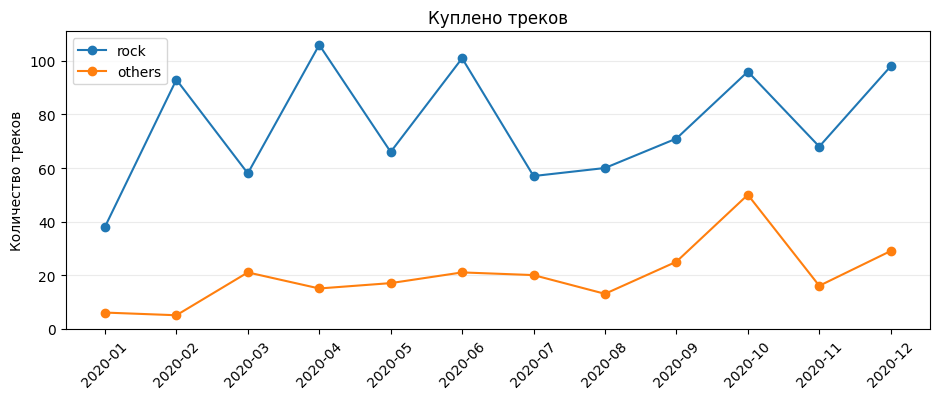

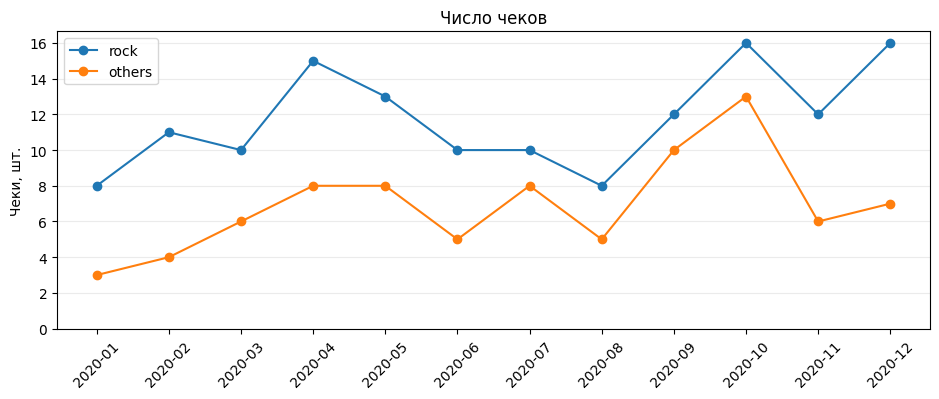

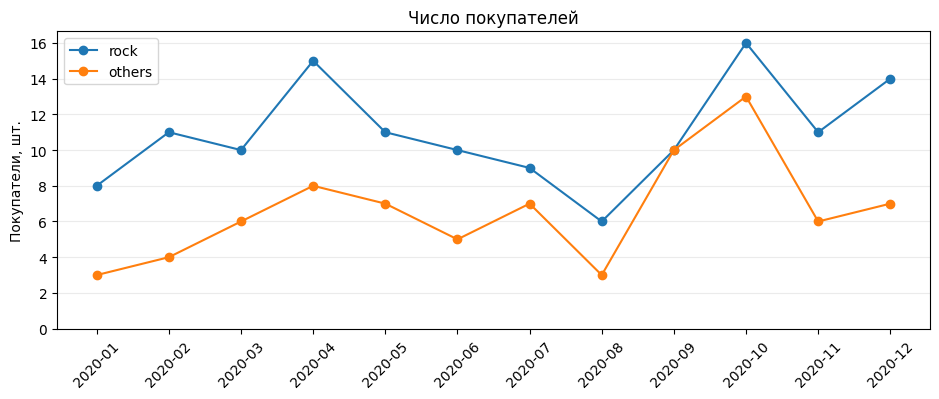

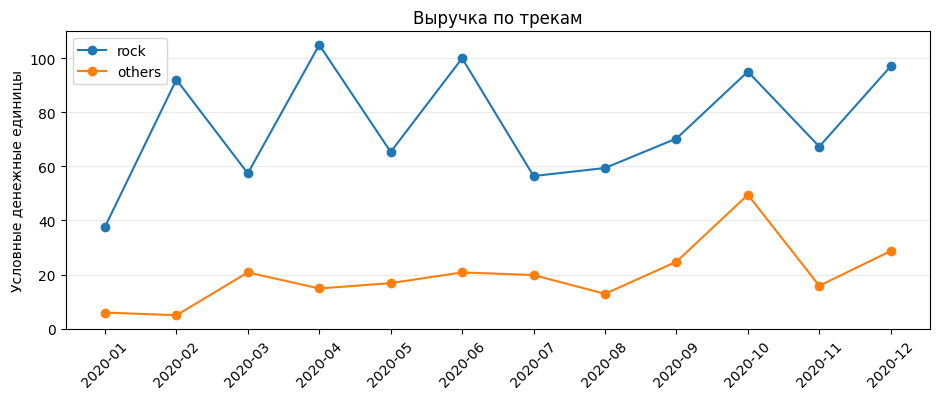

In [5]:
months = sorted(monthly.month.unique())
for metric, heading, y_label in [
    ('tracks','Куплено треков','Количество треков'),
    ('receipts','Число чеков','Чеки, шт.'),
    ('buyers','Число покупателей','Покупатели, шт.'),
    ('revenue','Выручка по трекам','Условные денежные единицы')
]:
    fig, ax = plt.subplots(figsize=(9.5, 4.1))
    for genre in ['rock', 'others']:
        part = monthly[monthly.genre_group == genre].set_index('month').reindex(months)
        ax.plot(months, part[metric], marker='o', label=genre)
    ax.set_title(heading)
    ax.set_ylabel(y_label)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=.25)
    ax.legend()
    ax.tick_params(axis='x', rotation=45)
    fig.tight_layout()
    plt.show()

## 5. Выводы

1. **`rock` лидирует во все месяцы 2020 года.** За год куплено 912 треков этой группы против 238 в `others` — 79,3% всех отобранных аудиотреков.
2. **У групп разные месяцы пиков.** У `rock` максимальное количество треков в апреле (106), у `others` — в октябре (50).
3. **Выручка меняется вслед за количеством треков.** Цена каждого трека в отобранной выборке — 0,99, поэтому средняя цена не объясняет разницу между месяцами.
4. **Колебания ≠ доказанная сезонность.** Один год позволяет увидеть месячные различия, но недостаточен для подтверждения повторяющегося сезонного эффекта. Для такого вывода надо сопоставить несколько лет.

**Практический результат:** SQL-витрина и интерактивная страница `dashboard.html` с переключением четырёх метрик. При желании можно повторить исследование на данных других лет.